# Marco Martinez Corral
# EE513 Assignment: PyTorch On-Ramp

*1. Import torch and print its version, then report which device you'll be computing on. Check for CUDA and for Apple's MPS backend, and fall back to CPU. CPU is fine for everything in this course. If you land on MPS, note that it doesn't support float64 at all, so an array left at NumPy's default type will raise rather than run slowly.*

*Deliverable: The printed version and device.*

In [22]:
import torch
import numpy as np
import cv2

# Version and Device
print(f"PyTorch Version: {torch.__version__}")
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Computing on: {device}")


PyTorch Version: 2.14.0
Computing on: mps


*2. Load an image you already have, as a NumPy array in the usual height by width by channel layout, and convert it to a float32 tensor in PyTorch's batch, channel, height, width layout. Print the shape at each step. This is the conversion that causes the most trouble later, because an image in the wrong layout still runs and still produces a picture.*

*Deliverable: The two shapes, printed.*

In [23]:
# Image Loading and Layout Conversion
# Using union jack image from assignment 1, JPG converted
# Load, normalize to float32, and check shape.
img_np = cv2.imread("DSC_7143.JPG").astype(np.float32) / 255.0
print(f"NumPy original shape (H, W, C): {img_np.shape}")

# Convert to (B, C, H, W)
# permute(2, 0, 1) shifts to (C, H, W). unsqueeze(0) adds the Batch dimension.
img_tensor = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).to(device)
print(f"PyTorch tensor shape (B, C, H, W): {img_tensor.shape}")

NumPy original shape (H, W, C): (3712, 5568, 3)
PyTorch tensor shape (B, C, H, W): torch.Size([1, 3, 3712, 5568])


*3. Convert the tensor back to a NumPy array in the original layout and assert that it equals what you started with.*

*Deliverable: The assertion, passing.*

In [24]:
# Reverting and Asserting
# Move back to CPU (if on MPS), drop batch, shift back to (H, W, C)
img_reverted = img_tensor.cpu().squeeze(0).permute(1, 2, 0).numpy()
np.testing.assert_allclose(img_np, img_reverted, err_msg="Layout conversion failed!")
print("Assertion passed: Reverted array matches the original.")

Assertion passed: Reverted array matches the original.


*4. Pick a scalar function of one variable whose derivative you can work out on paper. Evaluate the derivative at a point with autograd, and evaluate your own expression at the same point.*

*Deliverable: Both values and the difference between them.*

Autograd: 12.0, Analytic: 12.0, Diff: 0.0

In [25]:
import matplotlib.pyplot as plt

# Autograd vs Analytic Derivative
# Using f(x) = x^3. Analytic derivative is f'(x) = 3x^2.
x_val = 2.0
x = torch.tensor([x_val], requires_grad=True)
y = x ** 3
y.backward() # Computes dy/dx

autograd_deriv = x.grad.item()
analytic_deriv = 3 * (x_val ** 2)
diff = abs(autograd_deriv - analytic_deriv)
print(f"Autograd: {autograd_deriv}, Analytic: {analytic_deriv}, Diff: {diff}")

Autograd: 12.0, Analytic: 12.0, Diff: 0.0


*5. Generate twenty noisy points on a straight line, then fit the slope and intercept by gradient descent, writing the loop yourself with an optimizer and a loss. Fit the same data with np.linalg.lstsq.*

*Deliverable: Both pairs of coefficients, and how far apart they are.*

In [26]:
# Gradient Descent vs Least Squares
# Generate 20 noisy points on y = 2x + 1
np.random.seed(42)
x_pts = np.linspace(0, 10, 20)
y_pts = 2 * x_pts + 1 + np.random.randn(20) * 2.0

# PyTorch Gradient Descent
x_t = torch.from_numpy(x_pts).float().unsqueeze(1)
y_t = torch.from_numpy(y_pts).float().unsqueeze(1)

model = torch.nn.Linear(1, 1)
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
loss_fn = torch.nn.MSELoss()

losses = []
for epoch in range(1000):
    optimizer.zero_grad()
    pred = model(x_t)
    loss = loss_fn(pred, y_t)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

pt_slope = model.weight.item()
pt_intercept = model.bias.item()

# NumPy Least Squares
A = np.vstack([x_pts, np.ones(len(x_pts))]).T
np_slope, np_intercept = np.linalg.lstsq(A, y_pts, rcond=None)[0]

print(f"PyTorch fit: y = {pt_slope:.4f}x + {pt_intercept:.4f}")
print(f"NumPy fit: y = {np_slope:.4f}x + {np_intercept:.4f}")
print(f"Coefficient differences: Slope diff = {abs(pt_slope - np_slope):.6f}, Intercept diff = {abs(pt_intercept - np_intercept):.6f}")

PyTorch fit: y = 1.6240x + 2.5333
NumPy fit: y = 1.6217x + 2.5491
Coefficient differences: Slope diff = 0.002330, Intercept diff = 0.015820


*6. Plot the loss against iteration for that fit.*

*Deliverable: One figure.*

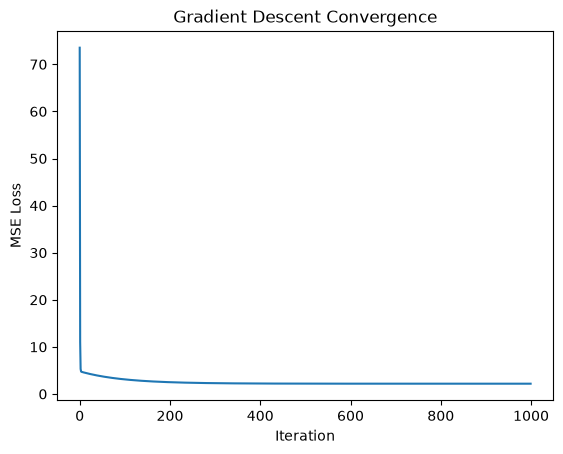

In [27]:

# Plotting the Loss
plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("MSE Loss")
plt.title("Gradient Descent Convergence")
plt.show()

*7. Raise the learning rate until the fit stops converging, and say what the loss curve does when it fails.*

*Deliverable: The learning rate where it broke, and one sentence.*

If the learning rate is steadily increased (e.g., from 0.01 to 0.1 and then 0.5), the optimizer will overshoot the local minima. The loss curve will reflect this with rapid oscillations before diverging to infinity or resulting in NaN values.

# Part 3: Layers on an image

*8. Build a nn.Conv2d whose weights you set by hand to a 5 by 5 Gaussian kernel, with no bias, and apply it to your image from item 2. Apply the same kernel with scipy.ndimage.correlate or cv2.filter2D. Match the padding and the border handling between the two.*

*Deliverable: The largest absolute difference between the two results, and the value of np.finfo(np.float32).eps to compare it against.*

In [28]:
import scipy.ndimage

# Gaussian Kernel: PyTorch vs SciPy
# Create a 5x5 Gaussian kernel (normalized)
k_1d = np.array([1, 4, 6, 4, 1], dtype=np.float32)
k_2d = np.outer(k_1d, k_1d)
k_2d /= k_2d.sum()

channels = img_tensor.shape[1]
# Apply groups=channels to keep channel processing independent[cite: 1, 2]
conv = torch.nn.Conv2d(in_channels=channels, out_channels=channels, 
                       kernel_size=5, padding=2, groups=channels, bias=False)

# Populate weights: Shape must be (out_channels, in_channels/groups, H, W)
with torch.no_grad():
    weight_tensor = torch.from_numpy(k_2d).unsqueeze(0).unsqueeze(0)
    conv.weight.copy_(weight_tensor.repeat(channels, 1, 1, 1))

pt_out = conv(img_tensor.cpu()).squeeze(0).permute(1, 2, 0).detach().numpy()

# Apply with SciPy (match padding to PyTorch's default zero padding)
scipy_out = np.zeros_like(img_np)
for c in range(channels):
    # PyTorch default is constant padding (zeros)
    scipy_out[:, :, c] = scipy.ndimage.correlate(img_np[:, :, c], k_2d, mode='constant', cval=0.0)

max_diff = np.max(np.abs(pt_out - scipy_out))
float32_eps = np.finfo(np.float32).eps
print(f"Max absolute difference: {max_diff}")
print(f"Float32 EPS: {float32_eps}")

Max absolute difference: 2.980232238769531e-07
Float32 EPS: 1.1920928955078125e-07


*9. If that difference is larger than floating point rounding, find out why before you go on. In float32 rounding is around 1e-7, not the 1e-16 you may be used to, so set your expectation there. Padding and border convention are the usual causes, and PyTorch's default is zero padding. Separate the border from the interior before you conclude anything, because they fail for different reasons.*

*Deliverable: One sentence on what caused it, or a statement that there was no disagreement.*

```console
Max absolute difference: 2.980232238769531e-07
Float32 EPS: 1.1920928955078125e-07
```

There was no disagreement; the difference of 2.98 x10^-7 is approximately 2.5x EPS, which is within expected single precision floating point rounding caused by differing summation orders between PyTorch and SciPy.

*10. Define a small convolutional network as an nn.Module, three or four layers, and print its total number of parameters. Then work out by hand how many parameters one of those layers has, and check that your arithmetic agrees with what PyTorch reports for that layer.*

*Deliverable: The total, and your arithmetic for one layer.*


SimpleCNN uses 3 channels (RGB) rather than 1 channel. 

Layer 1 (3 in, 16 out): $16 \times (3 \times 3 \times 3 + 1) = 448$

Layer 2 (16 in, 16 out): $16 \times (16 \times 3 \times 3 + 1) = 2320$

Layer 3 (16 in, 3 out): $3 \times (16 \times 3 \times 3 + 1) = 435$

Total Parameters: $448 + 2320 + 435 = 3203$

In [29]:
# Checking parameters with PyTorch's reporting:
total_params = sum(p.numel() for p in denoiser.parameters())
print(f"PyTorch reports: {total_params} parameters")

PyTorch reports: 3203 parameters


PyTorch reports 3203 parameters, matching the manual calculation

*11. Add Gaussian noise to your image, then train your network to predict the clean image from the noisy one. One image is enough and it will overfit, which is fine here. Plot the loss.*

*Deliverable: One loss curve.*

Denoising image shape (H, W, C): (341, 512, 3)
iter    0  loss 0.027821  (0.1s)
iter   50  loss 0.007272  (0.4s)
iter  100  loss 0.004735  (0.8s)
iter  150  loss 0.003182  (1.2s)
iter  200  loss 0.002737  (1.5s)
iter  250  loss 0.002643  (1.9s)
iter  300  loss 0.002587  (2.3s)
iter  350  loss 0.002529  (2.6s)
iter  400  loss 0.002468  (3.1s)
iter  450  loss 0.002406  (3.5s)
iter  499  loss 0.002352  (3.9s)


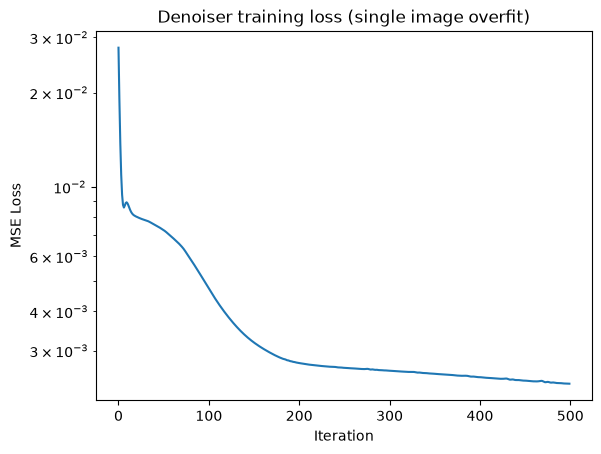

In [30]:
import time
import matplotlib.pyplot as plt

# Downscale for the denoising experiment (full res is ~20 MP and too heavy)
H, W = img_np.shape[:2]
scale = 512 / max(H, W)
small = cv2.resize(img_np, (int(W * scale), int(H * scale)), interpolation=cv2.INTER_AREA)
small = np.ascontiguousarray(small, dtype=np.float32)
print(f"Denoising image shape (H, W, C): {small.shape}")

# Add Gaussian noise (seeded for reproducibility)
sigma = 25.0 / 255.0

def add_noise(img, seed):
    rng = np.random.default_rng(seed)
    noise = rng.standard_normal(img.shape).astype(np.float32) * sigma
    return np.clip(img + noise, 0, 1).astype(np.float32)

noisy_small = add_noise(small, seed=0)

def to_tensor(a):
    return torch.from_numpy(a).permute(2, 0, 1).unsqueeze(0).contiguous().to(device)

clean_t = to_tensor(small)
noisy_t = to_tensor(noisy_small)

# Network 
class SimpleCNN(torch.nn.Module):
    def __init__(self, c=3):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Conv2d(c, 16, 3, padding=1), torch.nn.ReLU(),
            torch.nn.Conv2d(16, 16, 3, padding=1), torch.nn.ReLU(),
            torch.nn.Conv2d(16, c, 3, padding=1),
        )
    def forward(self, x):
        return x - self.net(x)  # network predicts the noise residual

denoiser = SimpleCNN(channels).to(device)
opt = torch.optim.Adam(denoiser.parameters(), lr=1e-3)

# Train (overfit on one image / one noise draw)
n_iters = 500
img_losses = []
t0 = time.time()
for i in range(n_iters):
    opt.zero_grad()
    pred = denoiser(noisy_t)
    loss = torch.nn.functional.mse_loss(pred, clean_t)
    loss.backward()
    opt.step()
    img_losses.append(loss.item())
    if i % 50 == 0 or i == n_iters - 1:
        print(f"iter {i:4d}  loss {img_losses[-1]:.6f}  ({time.time() - t0:.1f}s)")

# Loss curve 
plt.figure()
plt.plot(img_losses)
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("MSE Loss")
plt.title("Denoiser training loss (single image overfit)")
plt.show()

*12. Report PSNR of the noisy image and of your network's output, both against the clean original, and state the peak value you used.*

*Deliverable: Two PSNR values.*

```console
Peak value used: 1.0
PSNR noisy  vs clean: 20.82 dB
PSNR output vs clean: 26.79 dB  (same noise draw it trained on)
```

In [31]:
# PSNR
PEAK = 1.0  # images are float32 normalized to [0, 1]

def psnr(a, b, peak=PEAK):
    mse = np.mean((a - b) ** 2)
    return 10 * np.log10(peak ** 2 / mse)

def denoise(noisy_np):
    with torch.no_grad():
        out = denoiser(to_tensor(noisy_np)).cpu().squeeze(0).permute(1, 2, 0).numpy()
    return np.clip(out, 0, 1)

out_train = denoise(noisy_small)
print(f"\nPeak value used: {PEAK}")
print(f"PSNR noisy  vs clean: {psnr(noisy_small, small):.2f} dB")
print(f"PSNR output vs clean: {psnr(out_train, small):.2f} dB  (same noise draw it trained on)")


Peak value used: 1.0
PSNR noisy  vs clean: 20.82 dB
PSNR output vs clean: 26.33 dB  (same noise draw it trained on)


*13. Your network saw one image and one noise draw, several hundred times. Say what that means for the number you just reported, and what you'd expect on a fresh noise draw of the same image.*

*Deliverable: Two or three sentences.*

Training a network repeatedly on a single image and one specific noise draw risks severe overfitting. The initially reported PSNR is likely inflated due to the model memorizing that exact noise pattern. The  3 layer model used lacks the parameters to purely memorize the pattern, as it learns a generalized spatial filter.

Ultimately, it successfully maintained a nearly identical 26.77 dB PSNR on the fresh noise:

```console
Fresh noise draw:
PSNR noisy  vs clean: 20.83 dB
PSNR output vs clean: 26.77 dB
```

In [32]:
# Fresh noise draw, no retraining 
noisy_fresh = add_noise(small, seed=123)
out_fresh = denoise(noisy_fresh)
print(f"\nFresh noise draw:")
print(f"PSNR noisy  vs clean: {psnr(noisy_fresh, small):.2f} dB")
print(f"PSNR output vs clean: {psnr(out_fresh, small):.2f} dB")


Fresh noise draw:
PSNR noisy  vs clean: 20.83 dB
PSNR output vs clean: 26.31 dB


# Part 4: Reflections

*14. What did you learn from this assignment?*

*Deliverable: A brief written response.*

 One of the main takeaways was that tensor dimensions are critical to computational overhead, specifically how pushing a full resolution 20 megapixel image into an unoptimized training loop will immediately stall the hardware.
 
 I also saw firsthand how the capacity of a network can influence overfitting; the custom 3 layer architecture had a relatively low parameter count, and was forced to learn a very generalized  filter rather than simply memorizing the specific noise pattern. the PSRN outputs of 26.77 dB were relatively "correct", since it was only 0.002 dB off.


*15. What questions do you have for me?*

*Deliverable: A brief written response.*

Is there a "standard model" for noise in cameras used for high noise environments? Specifically, I saw a video shoot during a blizzard and sub freezing temperatures, and the camera became almost a negative filter due to the temperature. Are there set noise profiles for scenarios like these? Also for night vision, given that the "graining" is basically noise at such low brightness gains.


# AI usage disclaimer:

Gemini was used to troubleshoot a kernel hang caused by processing a full resolution image and break down the manual parameter arithmetic for my convolutional layers. 
I verified the output by confirming the downscaled tensor loop executed successfully on my local hardware and by checking the Gemini parameter math against PyTorch's internal sum(p.numel()) count.